# Task 1.2 — Data Cleaning & EDA (Titanic Passenger Dataset)
**Week 1 · AI/ML Internship (Skill Set Go EduTech)** · Author: Neela Vyshali

**Objective.** Clean a real-world dataset and explore it with **NumPy, Pandas and Matplotlib** to uncover patterns and anomalies.

**Deliverable.** This Jupyter notebook + the cleaned dataset (`titanic_cleaned.csv`) + visualizations.

**Dataset.** Passenger records of the RMS Titanic (891 passengers, 12 columns) — a real dataset with missing values, skewed numeric columns and text fields that need cleaning.
Source: `datasciencedojo/datasets` on GitHub (the notebook downloads it automatically).

**Workflow:** 1) Load → 2) Inspect → 3) Clean (documented step by step) → 4) Validate → 5) Explore (univariate, bivariate, correlation) → 6) Insights → 7) Save cleaned data.

| Column | Meaning |
|---|---|
| PassengerId, Name, Ticket | identifiers / text |
| Survived | 0 = died, 1 = survived (target) |
| Pclass | ticket class (1 = highest) |
| Sex, Age | demographics |
| SibSp, Parch | siblings/spouses and parents/children aboard |
| Fare, Cabin, Embarked | ticket price, cabin number, port of embarkation |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Load the data

In [2]:
URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
raw = pd.read_csv(URL)
print("shape:", raw.shape)
raw.head()

shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Initial inspection

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
raw.describe().round(2)

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


,missing,percent
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2


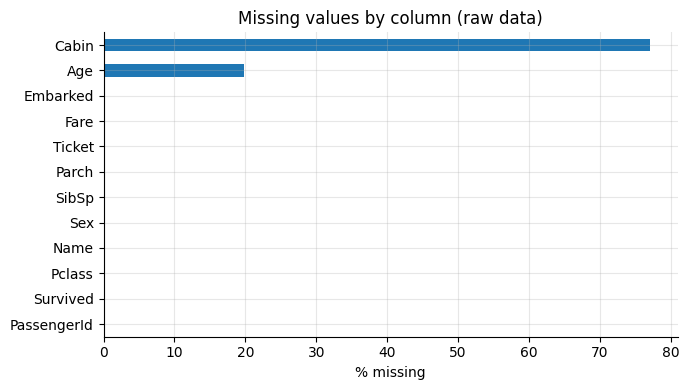

In [5]:
missing = pd.DataFrame({"missing": raw.isna().sum(), "percent": (raw.isna().mean() * 100).round(1)})
display(missing[missing["missing"] > 0].sort_values("missing", ascending=False))

ax = (raw.isna().mean() * 100).sort_values().plot.barh(color="C0")
ax.set_xlabel("% missing"); ax.set_title("Missing values by column (raw data)")
plt.tight_layout(); plt.show()

**What the inspection shows**
- `Cabin` is missing for most passengers, `Age` for about one in five, and `Embarked` for just 2 rows.
- `Fare` is heavily right-skewed (mean far above the median) and includes `0` values.
- `Name` holds a title (Mr, Mrs, Miss …) that can be turned into a useful feature.
- Column names are inconsistent (`SibSp`, `Parch`, `PassengerId`), so they need to be standardised.

## 3. Data cleaning (step by step)

### Step 1 — Standardise column names and work on a copy

In [6]:
df = raw.copy()
df.columns = df.columns.str.strip().str.lower()
df = df.rename(columns={"passengerid": "passenger_id", "sibsp": "siblings_spouses", "parch": "parents_children"})
print(list(df.columns))

['passenger_id', 'survived', 'pclass', 'name', 'sex', 'age', 'siblings_spouses', 'parents_children', 'ticket', 'fare', 'cabin', 'embarked']


### Step 2 — Check duplicates and invalid categories
Shared tickets are expected (families/groups travelled together), so only full-row and ID duplicates are errors.

In [7]:
print("full-row duplicates      :", df.duplicated().sum())
print("duplicate passenger IDs  :", df["passenger_id"].duplicated().sum())
print("rows sharing a ticket    :", df["ticket"].duplicated(keep=False).sum(), "(groups/families, not errors)")
print("categories -> sex:", sorted(df["sex"].unique()), "| embarked:", sorted(df["embarked"].dropna().unique()),
      "| pclass:", sorted(df["pclass"].unique()))

full-row duplicates      : 0
duplicate passenger IDs  : 0
rows sharing a ticket    : 344 (groups/families, not errors)
categories -> sex: ['female', 'male'] | embarked: ['C', 'Q', 'S'] | pclass: [np.int64(1), np.int64(2), np.int64(3)]


### Step 3 — `embarked`: 2 missing values → fill with the most frequent port (mode)
Only 2 rows are affected, so the mode is a safe, low-impact choice.

In [8]:
n_embarked_missing = df["embarked"].isna().sum()
mode_port = df["embarked"].mode()[0]
df["embarked"] = df["embarked"].fillna(mode_port)
df["embarked_port"] = df["embarked"].map({"S": "Southampton", "C": "Cherbourg", "Q": "Queenstown"})
print(f"filled {n_embarked_missing} rows with '{mode_port}'"); print(df["embarked_port"].value_counts())

filled 2 rows with 'S'


embarked_port
Southampton    646
Cherbourg      168
Queenstown      77
Name: count, dtype: int64


### Step 4 — `cabin`: ~77% missing → keep the *information* (has a cabin? which deck?) and drop the raw column
Imputing a cabin number would be inventing data. A "has_cabin" flag and the deck letter preserve what is known.

In [9]:
n_cabin_missing = df["cabin"].isna().sum()
df["has_cabin"] = df["cabin"].notna().astype(int)
df["deck"] = df["cabin"].str[0].fillna("Unknown")
df = df.drop(columns="cabin")
print(f"{n_cabin_missing} cabin values missing ({n_cabin_missing / len(df):.1%}) -> replaced by has_cabin + deck")
print(df["deck"].value_counts().to_dict())

687 cabin values missing (77.1%) -> replaced by has_cabin + deck
{'Unknown': 687, 'C': 59, 'B': 47, 'D': 33, 'E': 32, 'A': 15, 'F': 13, 'G': 4, 'T': 1}


### Step 5 — Extract a passenger `title` from `name` (regex) and group rare titles

In [10]:
df["title"] = df["name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
df["title"] = df["title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
core_titles = ["Mr", "Miss", "Mrs", "Master"]
df.loc[~df["title"].isin(core_titles), "title"] = "Rare"      # Dr, Rev, Col, Major, Countess ...
print(df["title"].value_counts())

title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64


### Step 6 — `age`: fill missing values with the **median age of the passenger's class and sex**
A single global median would ignore that first-class passengers were older. Group-wise medians keep those differences. An `age_was_missing` flag records which rows were imputed.

In [11]:
display(df.groupby(["pclass", "sex"])["age"].median().unstack().round(1).rename_axis(index="pclass", columns="median age"))

n_age_missing = df["age"].isna().sum()
df["age_was_missing"] = df["age"].isna().astype(int)
df["age"] = df["age"].fillna(df.groupby(["pclass", "sex"])["age"].transform("median"))
print(f"imputed {n_age_missing} ages | remaining missing: {df['age'].isna().sum()}")

median age,female,male
pclass,,
1,35.0,40.0
2,28.0,30.0
3,21.5,25.0


imputed 177 ages | remaining missing: 0


### Step 7 — Feature engineering

In [12]:
df["family_size"] = df["siblings_spouses"] + df["parents_children"] + 1
df["is_alone"] = (df["family_size"] == 1).astype(int)
df["age_group"] = pd.cut(df["age"], bins=[0, 12, 18, 35, 60, 100],
                         labels=["Child (0-12)", "Teen (13-18)", "Young adult (19-35)", "Adult (36-60)", "Senior (>60)"])
df["log_fare"] = np.log1p(df["fare"])          # tames the heavy right skew
df[["age", "age_group", "family_size", "is_alone", "fare", "log_fare"]].head()

,age,age_group,family_size,is_alone,fare,log_fare
0,22.0,Young adult (19-35),2,0,7.2500,2.110213
1,38.0,Adult (36-60),2,0,71.2833,4.280593
2,26.0,Young adult (19-35),1,1,7.9250,2.188856
3,35.0,Young adult (19-35),2,0,53.1000,3.990834
4,35.0,Young adult (19-35),1,1,8.0500,2.202765


### Step 8 — Detect anomalies and outliers (NumPy)
Suspicious values are **flagged, not deleted**, unless they are clearly errors.

In [13]:
# (a) zero fares
n_zero_fare = int((df["fare"] == 0).sum())
df["fare_zero"] = np.where(df["fare"] == 0, 1, 0)

# (b) fare outliers using the IQR rule
q1, q3 = np.percentile(df["fare"], [25, 75])
upper = q3 + 1.5 * (q3 - q1)
df["fare_outlier"] = np.where(df["fare"] > upper, 1, 0)

# (c) age outliers using z-scores
z_age = (df["age"] - df["age"].mean()) / df["age"].std()
n_age_out = int((np.abs(z_age) > 3).sum())

print(f"zero fares          : {n_zero_fare} passengers (pclass mix: {df.loc[df.fare_zero == 1, 'pclass'].value_counts().to_dict()})")
print(f"fare IQR upper fence: {upper:.2f} -> {df['fare_outlier'].sum()} outliers, max fare = {df['fare'].max():.2f}")
print(f"age |z| > 3         : {n_age_out} passengers (oldest = {df['age'].max():.0f}); infants under 1 year: {int((df['age'] < 1).sum())}")
print("large families      : max siblings/spouses =", df["siblings_spouses"].max(), "| max family_size =", df["family_size"].max())

zero fares          : 15 passengers (pclass mix: {2: 6, 1: 5, 3: 4})
fare IQR upper fence: 65.63 -> 116 outliers, max fare = 512.33
age |z| > 3         : 7 passengers (oldest = 80); infants under 1 year: 7
large families      : max siblings/spouses = 8 | max family_size = 11


**Decisions.** Zero fares and very high fares are plausible (crew/complimentary tickets, luxury suites) so they stay and are flagged. Ages under 1 year are real infants (ages given as fractions). Large family sizes are real (one family of 11 travelled together). The skew is handled with `log_fare` instead of removing rows.

### Step 9 — Fix data types

In [14]:
for col in ["sex", "embarked", "embarked_port", "title", "deck"]:
    df[col] = df[col].astype("category")
df["survived"] = df["survived"].astype(int)
df.dtypes

passenger_id           int64
survived               int64
pclass                 int64
name                     str
sex                 category
age                  float64
siblings_spouses       int64
parents_children       int64
ticket                   str
fare                 float64
embarked            category
embarked_port       category
has_cabin              int64
deck                category
title               category
age_was_missing        int64
family_size            int64
is_alone               int64
age_group           category
log_fare             float64
fare_zero              int64
fare_outlier           int64
dtype: object

## 4. Validation and cleaning summary

In [15]:
assert df.isna().sum().sum() == 0, "there are still missing values"
assert df["passenger_id"].is_unique
assert set(df["survived"].unique()) <= {0, 1}
assert df["age"].between(0.1, 100).all() and (df["fare"] >= 0).all()

summary = pd.DataFrame({
    "step": ["Rename columns", "Embarked missing", "Cabin missing", "Age missing", "Title from name",
             "Feature engineering", "Anomaly flags"],
    "issue found": ["inconsistent names", f"{n_embarked_missing} rows", f"{n_cabin_missing} rows ({n_cabin_missing/len(df):.0%})",
                    f"{n_age_missing} rows ({n_age_missing/len(df):.0%})", "title hidden inside name",
                    "no family / age-band features", f"{n_zero_fare} zero fares, {int(df['fare_outlier'].sum())} fare outliers"],
    "action": ["snake_case names", "filled with mode (S)", "has_cabin flag + deck; column dropped",
               "median by class & sex + age_was_missing flag", "regex extract; rare titles grouped",
               "family_size, is_alone, age_group, log_fare", "flagged (not removed)"]})
display(summary)
print(f"\nBefore: {raw.shape[0]} rows x {raw.shape[1]} cols, {int(raw.isna().sum().sum())} missing cells")
print(f"After : {df.shape[0]} rows x {df.shape[1]} cols, {int(df.isna().sum().sum())} missing cells")

,step,issue found,action
0,Rename columns,inconsistent names,snake_case names
1,Embarked missing,2 rows,filled with mode (S)
2,Cabin missing,687 rows (77%),has_cabin flag + deck; column dropped
3,Age missing,177 rows (20%),median by class & sex + age_was_missing flag
4,Title from name,title hidden inside name,regex extract; rare titles grouped
5,Feature engineering,no family / age-band features,"family_size, is_alone, age_group, log_fare"
6,Anomaly flags,"15 zero fares, 116 fare outliers",flagged (not removed)



Before: 891 rows x 12 cols, 866 missing cells
After : 891 rows x 22 cols, 0 missing cells


## 5. Exploratory Data Analysis

### 5.1 Univariate — distributions before and after cleaning

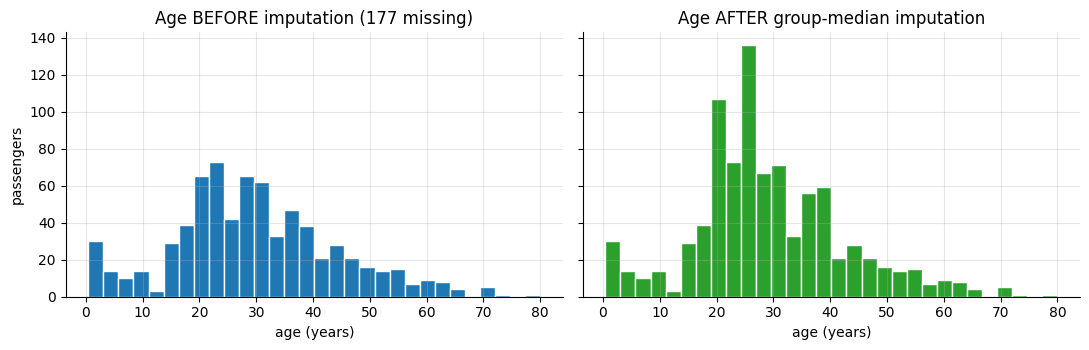

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
ax[0].hist(raw["Age"].dropna(), bins=30, color="C0", edgecolor="white")
ax[0].set_title(f"Age BEFORE imputation ({int(raw['Age'].isna().sum())} missing)")
ax[1].hist(df["age"], bins=30, color="C2", edgecolor="white")
ax[1].set_title("Age AFTER group-median imputation")
for a in ax: a.set_xlabel("age (years)")
ax[0].set_ylabel("passengers"); plt.tight_layout(); plt.show()

The imputation adds a visible spike near the median ages but keeps the overall shape (young adults dominate).

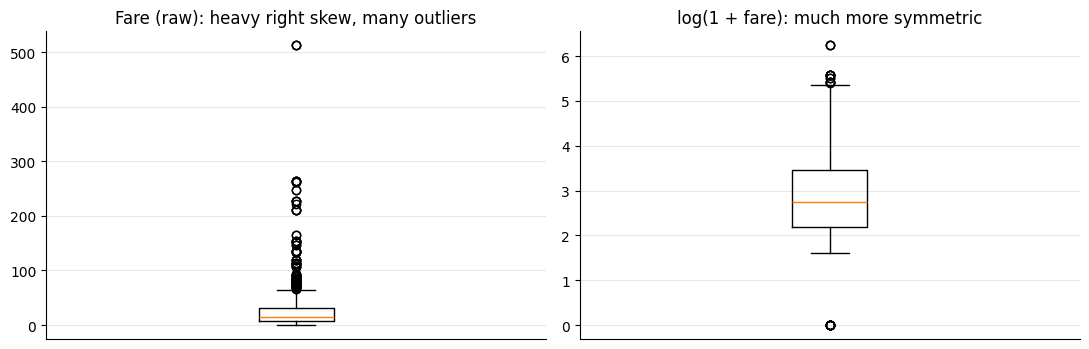

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].boxplot(df["fare"]);      ax[0].set_title("Fare (raw): heavy right skew, many outliers")
ax[1].boxplot(df["log_fare"]);  ax[1].set_title("log(1 + fare): much more symmetric")
for a in ax: a.set_xticks([])
plt.tight_layout(); plt.show()

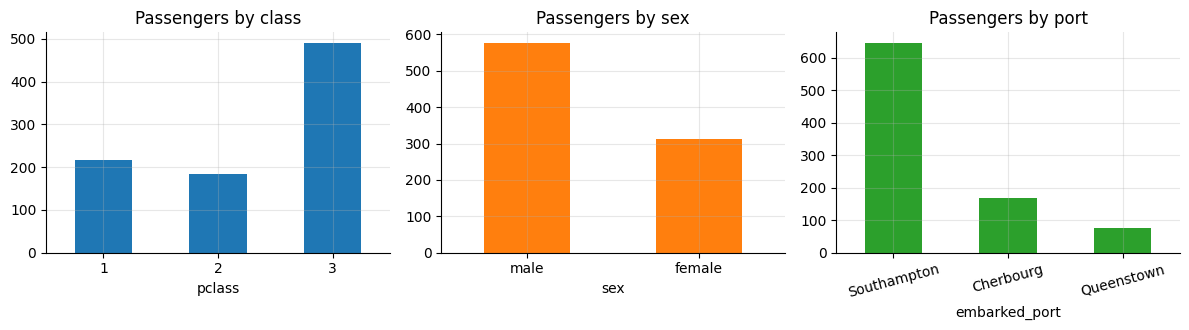

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
df["pclass"].value_counts().sort_index().plot.bar(ax=ax[0], color="C0", rot=0, title="Passengers by class")
df["sex"].value_counts().plot.bar(ax=ax[1], color="C1", rot=0, title="Passengers by sex")
df["embarked_port"].value_counts().plot.bar(ax=ax[2], color="C2", rot=15, title="Passengers by port")
plt.tight_layout(); plt.show()

### 5.2 Bivariate — what relates to survival?

Overall survival rate: 38.4%


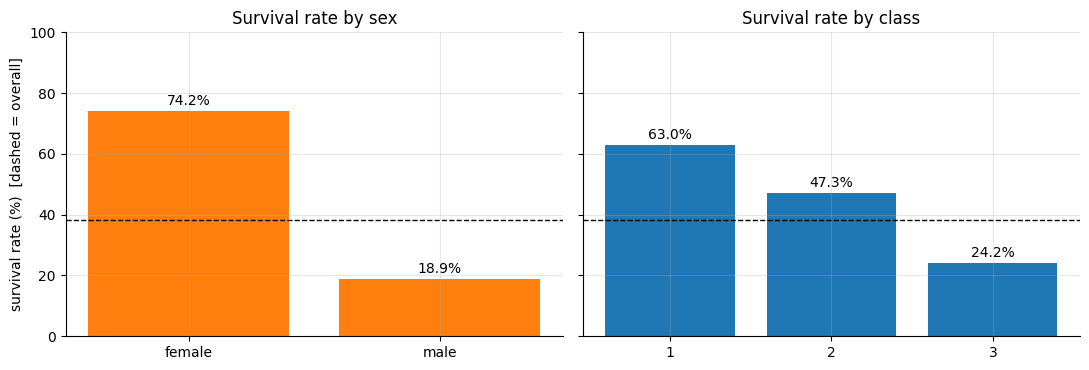

In [19]:
overall = df["survived"].mean()
print(f"Overall survival rate: {overall:.1%}")

def rate_bar(ax, rates, title, color="C0", rot=0):
    bars = ax.bar(rates.index.astype(str), rates.values * 100, color=color)
    ax.bar_label(bars, fmt="%.1f%%", padding=2)
    ax.axhline(overall * 100, color="k", ls="--", lw=1)
    ax.set_ylim(0, 100); ax.set_title(title); ax.tick_params(axis="x", rotation=rot)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
rate_bar(ax[0], df.groupby("sex", observed=True)["survived"].mean(), "Survival rate by sex", "C1")
rate_bar(ax[1], df.groupby("pclass", observed=True)["survived"].mean(), "Survival rate by class", "C0")
ax[0].set_ylabel("survival rate (%)  [dashed = overall]"); plt.tight_layout(); plt.show()

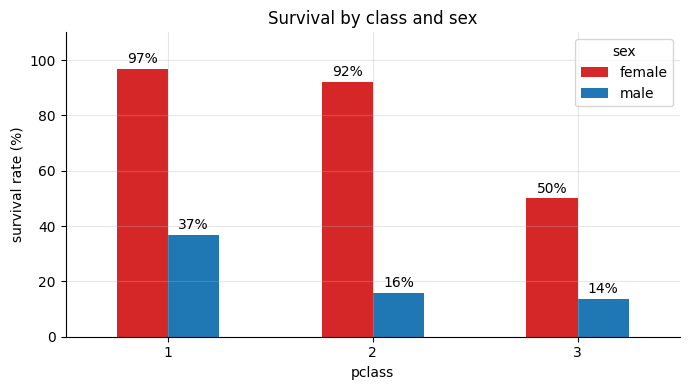

In [20]:
pivot = df.pivot_table(index="pclass", columns="sex", values="survived", aggfunc="mean", observed=True) * 100
ax = pivot.plot.bar(rot=0, color=["C3", "C0"], figsize=(7, 4))
for c in ax.containers: ax.bar_label(c, fmt="%.0f%%", padding=2)
ax.set_ylim(0, 110); ax.set_ylabel("survival rate (%)"); ax.set_title("Survival by class and sex")
plt.tight_layout(); plt.show()

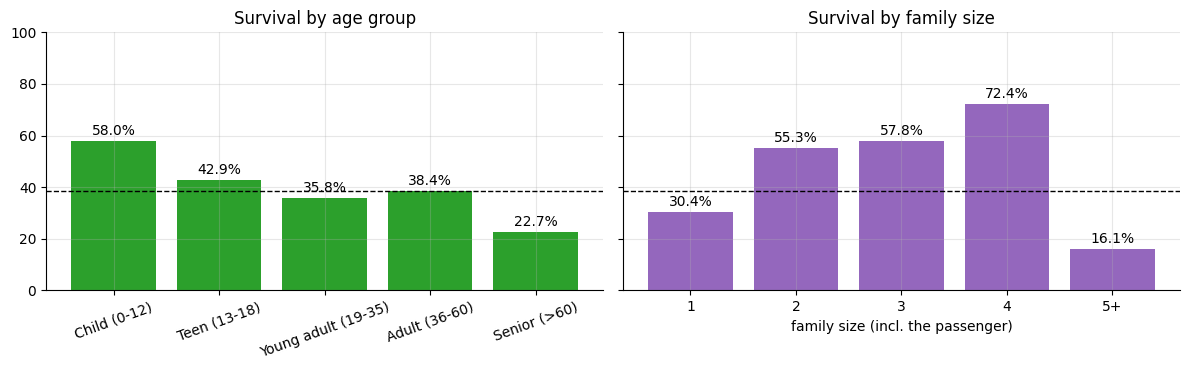

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
rate_bar(ax[0], df.groupby("age_group", observed=True)["survived"].mean(), "Survival by age group", "C2", rot=20)

fam = df["family_size"].clip(upper=5).map(lambda v: "5+" if v == 5 else str(v))
fam_rate = df.groupby(fam)["survived"].mean().reindex(["1", "2", "3", "4", "5+"])
rate_bar(ax[1], fam_rate, "Survival by family size", "C4")
ax[1].set_xlabel("family size (incl. the passenger)")
plt.tight_layout(); plt.show()

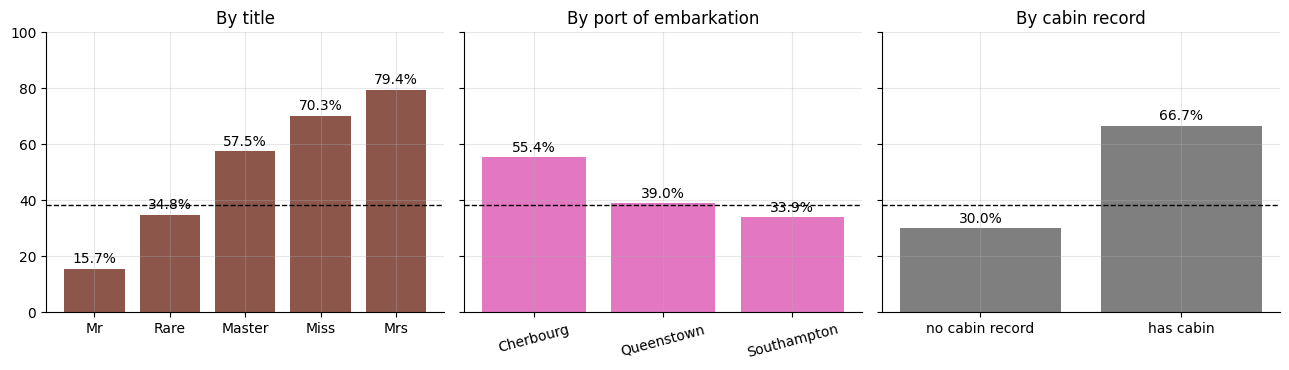

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
rate_bar(ax[0], df.groupby("title", observed=True)["survived"].mean().sort_values(), "By title", "C5")
rate_bar(ax[1], df.groupby("embarked_port", observed=True)["survived"].mean(), "By port of embarkation", "C6", rot=15)
rate_bar(ax[2], df.groupby("has_cabin")["survived"].mean().rename({0: "no cabin record", 1: "has cabin"}), "By cabin record", "C7")
plt.tight_layout(); plt.show()

### 5.3 Correlation heatmap (NumPy `corrcoef`)

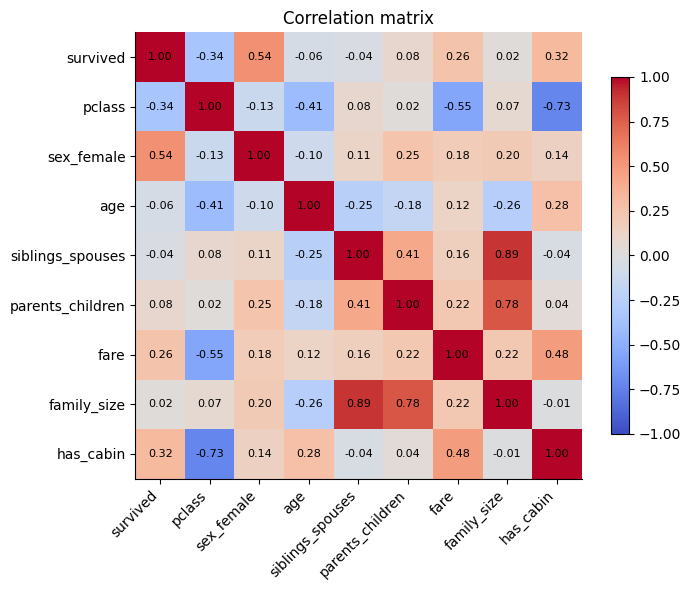

Correlation with survived (strongest first):
sex_female          0.543
pclass             -0.338
has_cabin           0.317
fare                0.257
parents_children    0.082
age                -0.060
siblings_spouses   -0.035
family_size         0.017
dtype: float64


In [23]:
cols = ["survived", "pclass", "sex_female", "age", "siblings_spouses", "parents_children", "fare", "family_size", "has_cabin"]
M = df.assign(sex_female=(df["sex"] == "female").astype(int))[cols].astype(float)
corr = np.corrcoef(M.values, rowvar=False)

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False); fig.colorbar(im, shrink=0.8); ax.set_title("Correlation matrix")
plt.tight_layout(); plt.show()

target_corr = pd.Series(corr[0, 1:], index=cols[1:]).sort_values(key=np.abs, ascending=False)
print("Correlation with survived (strongest first):"); print(target_corr.round(3))

## 6. Key insights

In [24]:
by_sex = df.groupby("sex", observed=True)["survived"].mean()
by_cls = df.groupby("pclass", observed=True)["survived"].mean()
by_age = df.groupby("age_group", observed=True)["survived"].mean()
by_cab = df.groupby("has_cabin")["survived"].mean()
by_ttl = df.groupby("title", observed=True)["survived"].mean()
by_prt = df.groupby("embarked_port", observed=True)["survived"].mean()
alone  = df.groupby("is_alone")["survived"].mean()
fam3_4 = df.loc[df["family_size"].between(2, 4), "survived"].mean()
fam5   = df.loc[df["family_size"] >= 5, "survived"].mean()
best_age = by_age.idxmax()
fc = pivot  # class x sex table (% survived)

display(Markdown(f'''
**Patterns**
1. **Sex was the strongest factor.** {by_sex["female"]:.1%} of women survived versus {by_sex["male"]:.1%} of men (overall {overall:.1%}).
2. **Class mattered.** Survival fell from {by_cls[1]:.1%} in 1st class to {by_cls[2]:.1%} in 2nd and {by_cls[3]:.1%} in 3rd. Even within a class women fared far better; 3rd-class women ({fc.loc[3, "female"]:.0f}%) survived more often than 1st-class men ({fc.loc[1, "male"]:.0f}%).
3. **Age:** the highest survival was in the **{best_age}** group ({by_age.max():.1%}); the lowest was in the **{by_age.idxmin()}** group ({by_age.min():.1%}).
4. **Family size:** passengers in families of 2-4 survived at {fam3_4:.1%}, travelling alone at {alone[1]:.1%}, and families of 5+ at only {fam5:.1%}.
5. **Titles tell the same story:** Mrs {by_ttl["Mrs"]:.1%}, Miss {by_ttl["Miss"]:.1%}, Master (boys) {by_ttl["Master"]:.1%}, but Mr only {by_ttl["Mr"]:.1%}.
6. **Cabin record:** passengers with a recorded cabin survived at {by_cab[1]:.1%} vs {by_cab[0]:.1%} without — mostly a proxy for 1st class.
7. **Port:** {by_prt.idxmax()} passengers had the highest survival ({by_prt.max():.1%}), largely because more of them travelled 1st class.

**Anomalies and data-quality findings**
- `Cabin` was {n_cabin_missing / len(raw):.0%} missing and `Age` {n_age_missing / len(raw):.0%} missing; both were handled without deleting any rows (891 rows kept).
- {n_zero_fare} passengers have a fare of 0 and {int(df["fare_outlier"].sum())} fares exceed the IQR fence of {upper:.1f} (maximum {df["fare"].max():.1f}); flagged, and `log_fare` created.
- No duplicate rows or IDs; shared tickets are groups travelling together.

**Limitations.** Age imputation reduces variance (visible spike), so age-based conclusions are approximate. This is observational data: the relationships above are associations, not causes.
'''))


**Patterns**
1. **Sex was the strongest factor.** 74.2% of women survived versus 18.9% of men (overall 38.4%).
2. **Class mattered.** Survival fell from 63.0% in 1st class to 47.3% in 2nd and 24.2% in 3rd. Even within a class women fared far better; 3rd-class women (50%) survived more often than 1st-class men (37%).
3. **Age:** the highest survival was in the **Child (0-12)** group (58.0%); the lowest was in the **Senior (>60)** group (22.7%).
4. **Family size:** passengers in families of 2-4 survived at 57.9%, travelling alone at 30.4%, and families of 5+ at only 16.1%.
5. **Titles tell the same story:** Mrs 79.4%, Miss 70.3%, Master (boys) 57.5%, but Mr only 15.7%.
6. **Cabin record:** passengers with a recorded cabin survived at 66.7% vs 30.0% without — mostly a proxy for 1st class.
7. **Port:** Cherbourg passengers had the highest survival (55.4%), largely because more of them travelled 1st class.

**Anomalies and data-quality findings**
- `Cabin` was 77% missing and `Age` 20% missing; both were handled without deleting any rows (891 rows kept).
- 15 passengers have a fare of 0 and 116 fares exceed the IQR fence of 65.6 (maximum 512.3); flagged, and `log_fare` created.
- No duplicate rows or IDs; shared tickets are groups travelling together.

**Limitations.** Age imputation reduces variance (visible spike), so age-based conclusions are approximate. This is observational data: the relationships above are associations, not causes.


## 7. Save the cleaned dataset

In [25]:
df.to_csv("titanic_cleaned.csv", index=False)
check = pd.read_csv("titanic_cleaned.csv")
print("saved titanic_cleaned.csv ->", check.shape, "| missing cells:", int(check.isna().sum().sum()))
check.head()

saved titanic_cleaned.csv -> (891, 22) | missing cells: 0


,passenger_id,survived,pclass,name,sex,age,siblings_spouses,parents_children,ticket,fare,embarked,embarked_port,has_cabin,deck,title,age_was_missing,family_size,is_alone,age_group,log_fare,fare_zero,fare_outlier
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,Southampton,0,Unknown,Mr,0,2,0,Young adult (19-35),2.110213,0,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,Cherbourg,1,C,Mrs,0,2,0,Adult (36-60),4.280593,0,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,Southampton,0,Unknown,Miss,0,1,1,Young adult (19-35),2.188856,0,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,Southampton,1,C,Mrs,0,2,0,Young adult (19-35),3.990834,0,0
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,Southampton,0,Unknown,Mr,0,1,1,Young adult (19-35),2.202765,0,0


## 8. Conclusion and next steps
The raw data was cleaned with documented, reversible decisions (nothing was silently dropped), validated with assertions, and explored with 9 figures (16 charts). The cleaned file `titanic_cleaned.csv` is ready for modelling — the next task (1.4) builds a classification model on this same problem.

**Possible improvements:** impute age with a model (e.g., regression on title, class and family size), engineer a ticket-group-size feature, and test whether the class effect remains after controlling for sex.